# Árbol de decisión (profundidad máxima = 4)
**Proyecto:** Análisis del catálogo de Netflix y la valoración de usuarios · UNIMINUTO Ibagué  
**Integrantes:** James Francois Lozano Gordillo · Elian Alexis Sandoval Durán

**Pregunta:** ¿Es posible predecir si un título tendrá una valoración *alta* a partir de sus características (género, tipo, duración, año, clasificación)? ¿Qué reglas usa el árbol?

**Decisiones de diseño (supuestos):**
- **Variable objetivo:** `alta` = 1 si `user_rating_score ≥ 85`, y 0 en caso contrario (clasificación binaria; umbral que deja las clases casi balanceadas).
- **Datos:** los 137 títulos de `netflix.csv` (sin duplicados y con puntuación) que cruzan por nombre con `netflix_titles.csv`, porque solo así se conoce el género, el tipo y la duración.
- **Modelo:** `DecisionTreeClassifier(max_depth=4, random_state=42)`.
- **Evaluación:** partición 70/30 estratificada y validación cruzada repetida (5 pliegues × 10 repeticiones), porque con 137 registros un solo conjunto de prueba (≈ 42 títulos) es muy inestable.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import os; os.makedirs('figs', exist_ok=True)
sns.set_theme(style='whitegrid'); ROJO, NEGRO, GRIS = '#B81D24', '#221F1F', '#8C8C8C'
SEMILLA = 42

## 1. Preparación de los datos

In [2]:
titulos = pd.read_csv('CSV/netflix_titles.csv').drop_duplicates()
valor = pd.read_csv('CSV/netflix.csv').drop_duplicates().dropna(subset=['user_rating_score'])

cat = titulos.drop_duplicates('title')[['title','type','listed_in','duration']]
m = valor.merge(cat, on='title', how='inner').copy()
print('Títulos con valoración y género:', len(m), '|', m.type.value_counts().to_dict())

# Variable objetivo
UMBRAL = 85
m['alta'] = (m.user_rating_score >= UMBRAL).astype(int)

# Variables explicativas
m['es_serie'] = (m.type == 'TV Show').astype(int)
dur = pd.to_numeric(m.duration.str.split(' ').str[0], errors='coerce')
m['temporadas'] = np.where(m.es_serie == 1, dur, 0)   # solo series
m['minutos']    = np.where(m.es_serie == 0, dur, 0)   # solo películas
m['infantil']   = m.rating.isin(['TV-Y','TV-Y7','TV-Y7-FV','TV-G','G']).astype(int)

# Géneros con al menos 5 títulos (una columna 0/1 por género)
gen = m.assign(g=m.listed_in.str.split(', ')).explode('g'); gen['g'] = gen.g.str.strip()
frecuentes = gen.groupby('g').title.nunique(); frecuentes = frecuentes[frecuentes >= 5].index.tolist()
for g in frecuentes:
    m['g_' + g] = m.listed_in.str.contains(g, regex=False).astype(int)

variables = ['release_year','rating_level','es_serie','temporadas','minutos','infantil'] + ['g_' + g for g in frecuentes]
X = m[variables].fillna(0); y = m.alta
print(f'Variables explicativas: {len(variables)} | Registros: {len(X)}')
bal = pd.DataFrame({'títulos': y.value_counts(), '%': (y.value_counts(normalize=True)*100).round(1)}).rename(index={0:'Baja (<85)', 1:'Alta (≥85)'}); print('Balance de la variable objetivo (1 = valoración alta ≥ 85):'); display(bal)

Títulos con valoración y género: 137 | {'TV Show': 108, 'Movie': 29}
Variables explicativas: 22 | Registros: 137
Balance de la variable objetivo (1 = valoración alta ≥ 85):


,títulos,%
alta,,
Alta (≥85),74,54.0
Baja (<85),63,46.0


## 2. Entrenamiento del árbol (max_depth = 4)

In [3]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
arbol = DecisionTreeClassifier(max_depth=4, random_state=SEMILLA).fit(Xtr, ytr)
print('Profundidad real del árbol:', arbol.get_depth(), '| Hojas:', arbol.get_n_leaves())
print(f'Entrenamiento: {len(Xtr)} títulos | Prueba: {len(Xte)} títulos')

Profundidad real del árbol: 4 | Hojas: 12
Entrenamiento: 95 títulos | Prueba: 42 títulos


## 3. El árbol

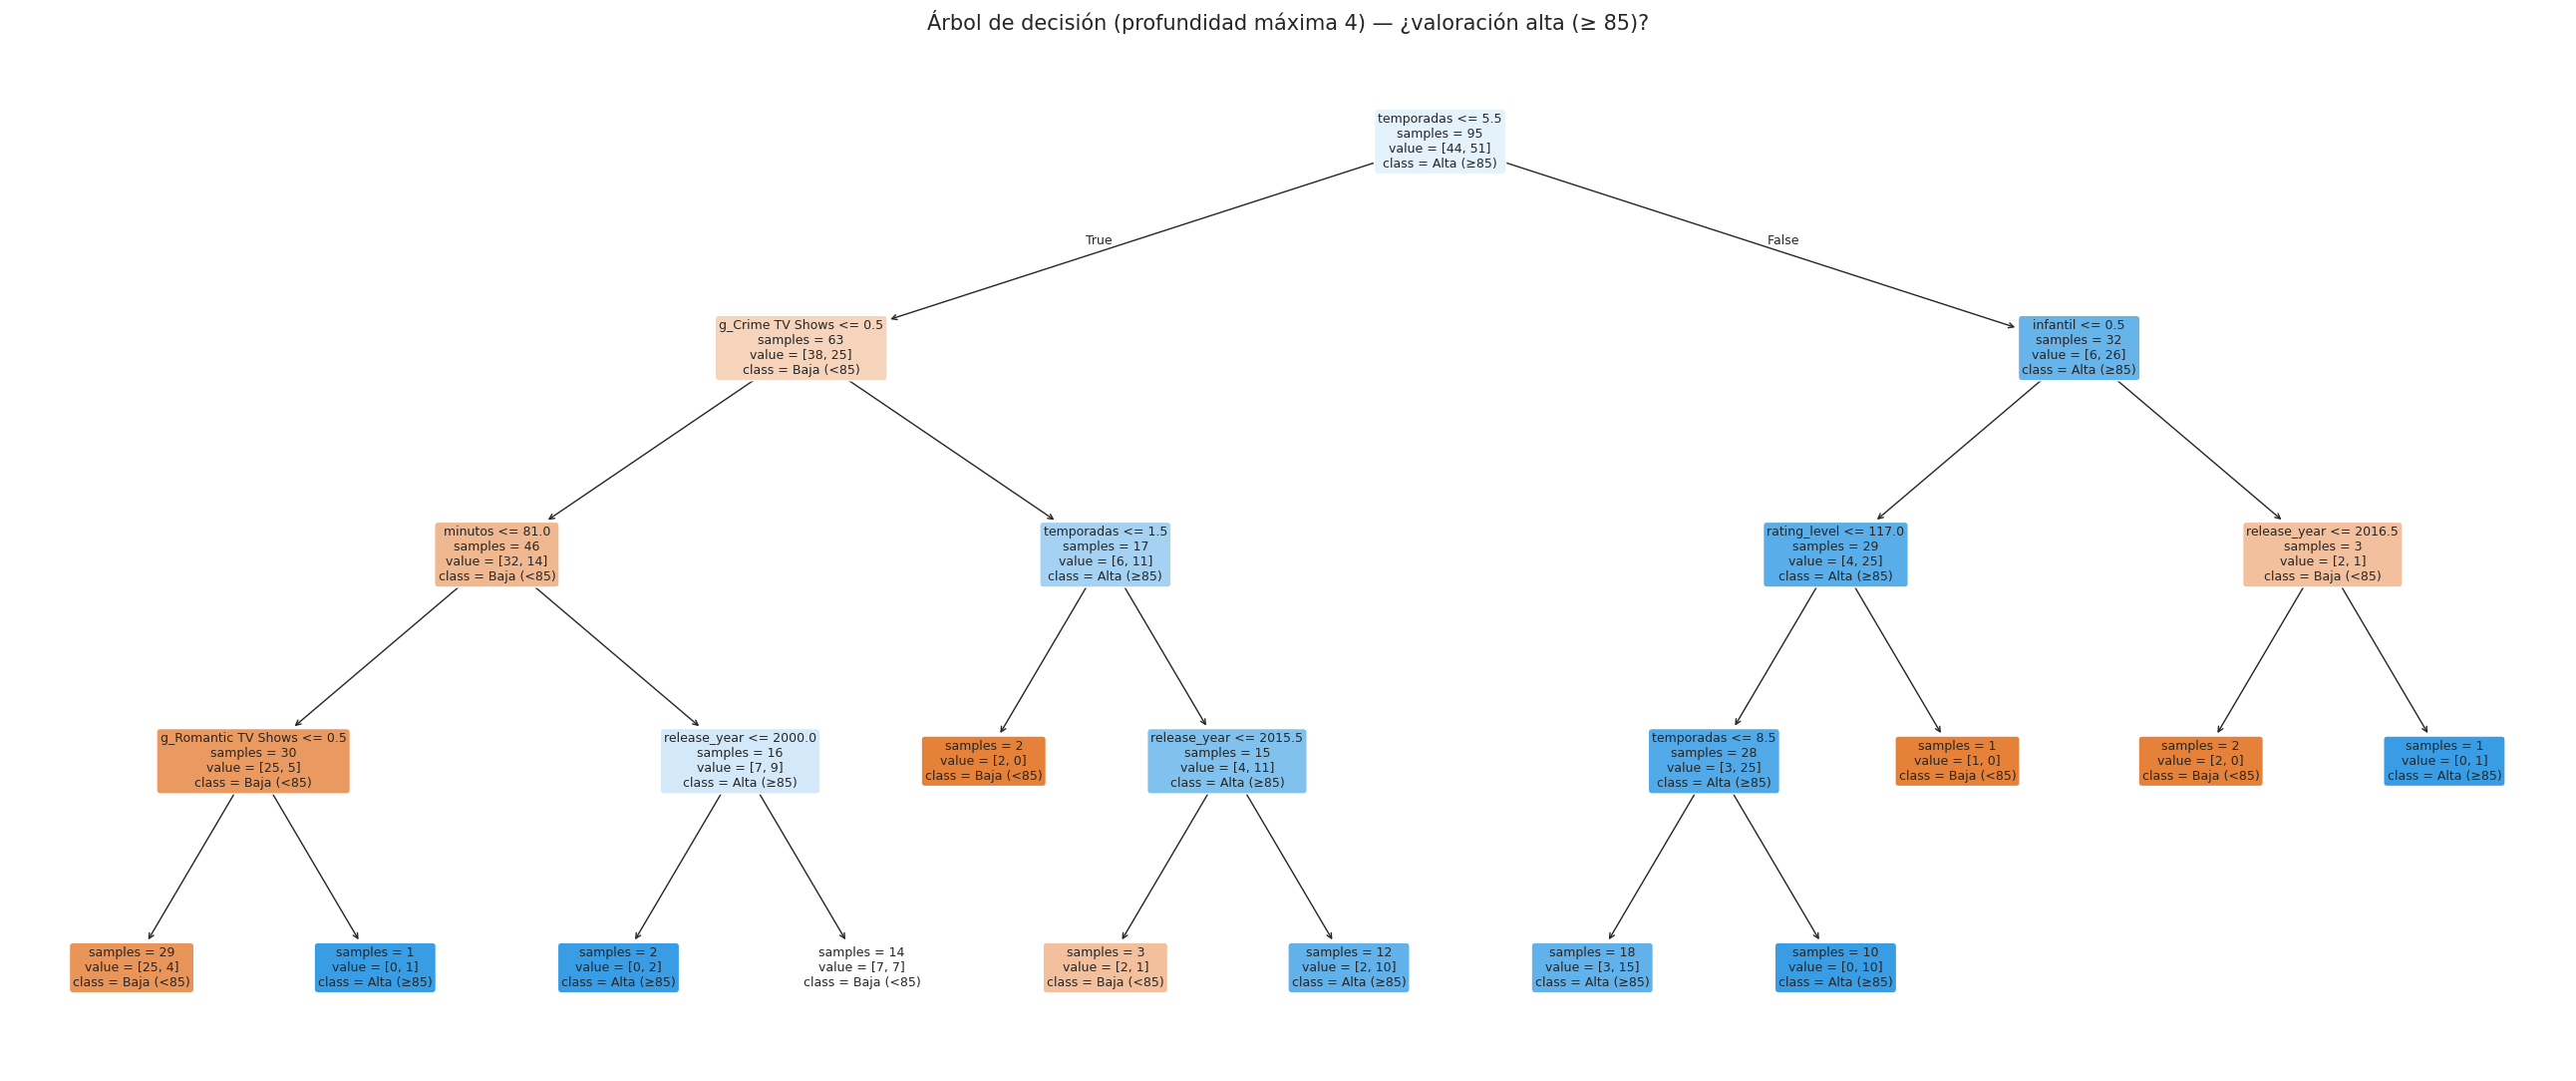

In [4]:
fig, ax = plt.subplots(figsize=(26, 11))
plot_tree(arbol, feature_names=variables, class_names=['Baja (<85)','Alta (≥85)'], filled=True, rounded=True,
          impurity=False, proportion=False, fontsize=9, ax=ax)
ax.set_title('Árbol de decisión (profundidad máxima 4) — ¿valoración alta (≥ 85)?', fontsize=15)
plt.tight_layout(); plt.savefig('figs/arbol_decision.png', dpi=150); plt.show()

In [5]:
print(export_text(arbol, feature_names=variables))

|--- temporadas <= 5.50
|   |--- g_Crime TV Shows <= 0.50
|   |   |--- minutos <= 81.00
|   |   |   |--- g_Romantic TV Shows <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- g_Romantic TV Shows >  0.50
|   |   |   |   |--- class: 1
|   |   |--- minutos >  81.00
|   |   |   |--- release_year <= 2000.00
|   |   |   |   |--- class: 1
|   |   |   |--- release_year >  2000.00
|   |   |   |   |--- class: 0
|   |--- g_Crime TV Shows >  0.50
|   |   |--- temporadas <= 1.50
|   |   |   |--- class: 0
|   |   |--- temporadas >  1.50
|   |   |   |--- release_year <= 2015.50
|   |   |   |   |--- class: 0
|   |   |   |--- release_year >  2015.50
|   |   |   |   |--- class: 1
|--- temporadas >  5.50
|   |--- infantil <= 0.50
|   |   |--- rating_level <= 117.00
|   |   |   |--- temporadas <= 8.50
|   |   |   |   |--- class: 1
|   |   |   |--- temporadas >  8.50
|   |   |   |   |--- class: 1
|   |   |--- rating_level >  117.00
|   |   |   |--- class: 0
|   |--- infantil >  0.50
|   |   |--- relea

## 4. Evaluación

Exactitud en entrenamiento : 0.821
Exactitud en prueba (30%)   : 0.595   (línea base «siempre la clase mayoritaria»: 0.548)
Validación cruzada (5x10)   : 0.589 ± 0.087   (línea base: 0.540)

Informe de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

  Baja (<85)       0.54      0.68      0.60        19
  Alta (≥85)       0.67      0.52      0.59        23

    accuracy                           0.60        42
   macro avg       0.60      0.60      0.60        42
weighted avg       0.61      0.60      0.59        42



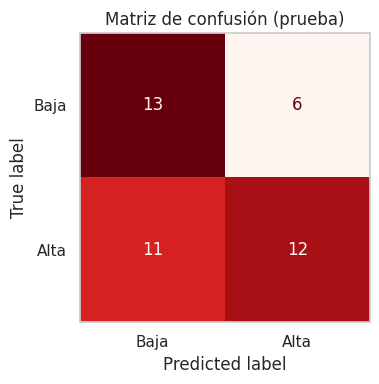

In [6]:
acc_tr, acc_te = arbol.score(Xtr, ytr), arbol.score(Xte, yte)
base = max(yte.mean(), 1 - yte.mean())
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA)
cv_arbol = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=SEMILLA), X, y, cv=cv)
base_cv = max(y.mean(), 1 - y.mean())
print(f'Exactitud en entrenamiento : {acc_tr:.3f}')
print(f'Exactitud en prueba (30%)   : {acc_te:.3f}   (línea base «siempre la clase mayoritaria»: {base:.3f})')
print(f'Validación cruzada (5x10)   : {cv_arbol.mean():.3f} ± {cv_arbol.std():.3f}   (línea base: {base_cv:.3f})')
print('\nInforme de clasificación (conjunto de prueba):')
print(classification_report(yte, arbol.predict(Xte), target_names=['Baja (<85)','Alta (≥85)']))
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(confusion_matrix(yte, arbol.predict(Xte)), display_labels=['Baja','Alta']).plot(ax=ax, cmap='Reds', colorbar=False)
ax.set_title('Matriz de confusión (prueba)'); ax.grid(False); plt.tight_layout(); plt.savefig('figs/arbol_confusion.png', dpi=170); plt.show()

### 4.1 ¿Por qué profundidad 4? Efecto de la profundidad

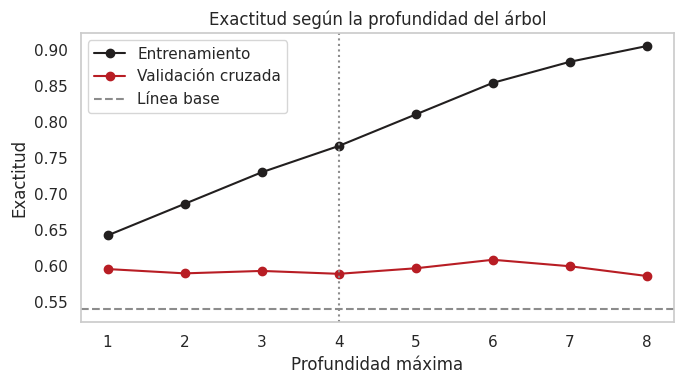

,profundidad,entrenamiento,validación cruzada
0,1,0.642,0.596
1,2,0.686,0.590
2,3,0.730,0.593
3,4,0.766,0.589
4,5,0.810,0.597
5,6,0.854,0.609
6,7,0.883,0.600
7,8,0.905,0.586


In [7]:
prof = range(1, 9); tr, te = [], []
for d in prof:
    mod = DecisionTreeClassifier(max_depth=d, random_state=SEMILLA)
    te.append(cross_val_score(mod, X, y, cv=cv).mean()); tr.append(mod.fit(X, y).score(X, y))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prof, tr, marker='o', color=NEGRO, label='Entrenamiento'); ax.plot(prof, te, marker='o', color=ROJO, label='Validación cruzada')
ax.axhline(base_cv, color=GRIS, ls='--', label='Línea base'); ax.axvline(4, color=GRIS, ls=':')
ax.set_xlabel('Profundidad máxima'); ax.set_ylabel('Exactitud'); ax.set_title('Exactitud según la profundidad del árbol'); ax.legend(); ax.grid(False)
plt.tight_layout(); plt.savefig('figs/arbol_profundidad.png', dpi=170); plt.show()
display(pd.DataFrame({'profundidad': list(prof), 'entrenamiento': np.round(tr,3), 'validación cruzada': np.round(te,3)}))

### 4.2 ¿Hace falta escalar las variables?

In [8]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
for nombre, esc in [('StandardScaler', StandardScaler()), ('MinMaxScaler', MinMaxScaler())]:
    esc.fit(Xtr)
    arbol_esc = DecisionTreeClassifier(max_depth=4, random_state=SEMILLA).fit(esc.transform(Xtr), ytr)
    iguales = (arbol.predict(Xte) == arbol_esc.predict(esc.transform(Xte))).all()
    misma_estructura = (arbol.tree_.feature == arbol_esc.tree_.feature).all() and (arbol.tree_.n_node_samples == arbol_esc.tree_.n_node_samples).all()
    print(f'{nombre}: mismas predicciones = {iguales} | misma estructura del árbol = {misma_estructura} | exactitud en prueba = {arbol_esc.score(esc.transform(Xte), yte):.3f}')

StandardScaler: mismas predicciones = True | misma estructura del árbol = True | exactitud en prueba = 0.595
MinMaxScaler: mismas predicciones = True | misma estructura del árbol = True | exactitud en prueba = 0.595


**Conclusión.** No se aplicó escalamiento porque el árbol decide con cortes del tipo `variable ≤ valor`, no con distancias: escalar solo cambia el valor numérico de cada corte, no a qué títulos separa. Con ambos escaladores el árbol resulta idéntico. El escalamiento sí será necesario en modelos basados en distancias o en coeficientes (k-vecinos, k-means, regresión regularizada).

## 5. Importancia de las variables

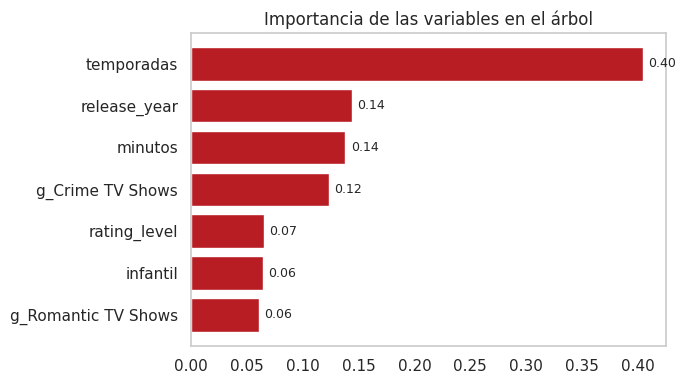

,importancia
temporadas,0.405
release_year,0.144
minutos,0.138
g_Crime TV Shows,0.123
rating_level,0.065
infantil,0.064
g_Romantic TV Shows,0.061


In [9]:
imp = pd.Series(arbol.feature_importances_, index=variables).sort_values(ascending=False)
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color=ROJO); ax.set_title('Importancia de las variables en el árbol'); ax.grid(False)
for i, v in enumerate(imp.values[::-1]): ax.text(v + .005, i, f'{v:.2f}', va='center', fontsize=9)
plt.tight_layout(); plt.savefig('figs/arbol_importancia.png', dpi=170); plt.show(); display(imp.round(3).to_frame('importancia'))

## 6. Interpretación

**Cómo se lee el árbol.** Es una cadena de preguntas de sí/no, de arriba hacia abajo. En cada recuadro, `samples` es la cantidad de títulos de entrenamiento (95) que llegan hasta allí y `value = [bajos, altos]` cuántos de ellos tienen valoración baja y alta. Azul = el árbol predice valoración alta; naranja = baja. `temporadas` vale 0 en películas y `minutos` vale 0 en series.

**Reglas con más respaldo (las hojas con más títulos):**
1. **Series de más de 5 temporadas:** 26 de 32 tienen valoración alta (81%). Si además no son infantiles y su nivel de clasificación es ≤ 117, son 25 de 28 (89%); con más de 8 temporadas, 10 de 10.
2. **Series de crimen con más de 1 temporada lanzadas después de 2015:** 10 de 12 con valoración alta (83%).
3. **Series de hasta 5 temporadas (o películas de ≤ 81 min) que no son de crimen ni de romance:** 25 de 29 con valoración baja (86%).

Estas reglas coinciden con lo que ya habíamos visto en el informe: más temporadas y géneros como crimen y romance se asocian con mejor valoración. Las variables más importantes son `temporadas` (0,41), `release_year` (0,14), `minutos` (0,14) y `g_Crime TV Shows` (0,12).

**Qué tan bien predice.**
- Exactitud en entrenamiento: 82,1%. En prueba: 59,5% (línea base de adivinar la clase mayoritaria: 54,8%). En validación cruzada: 58,9% ± 8,7 (línea base: 54,0%).
- La diferencia entre entrenamiento y prueba indica **sobreajuste**: el árbol memoriza parte de los 95 títulos de entrenamiento. 7 de sus 12 hojas tienen 3 títulos o menos, así que esas reglas no son confiables (por ejemplo, la hoja con 14 películas de más de 81 min lanzadas después de 2000 está empatada 7–7).
- El gráfico de profundidad lo confirma: la exactitud de entrenamiento sube de 0,64 a 0,91 al aumentar la profundidad, pero la de validación cruzada se queda en 0,59–0,61 sin importar la profundidad. Una profundidad mayor a 4 solo memoriza más.
- En prueba, el árbol acierta mejor las valoraciones bajas (recall 0,68) que las altas (0,52).

**Conclusión.** Con profundidad 4, el árbol sirve como **herramienta descriptiva** para encontrar segmentos (series largas bien valoradas; series cortas sin crimen ni romance peor valoradas), pero **es un predictor débil**: supera por solo unos 5 puntos a adivinar la clase mayoritaria, y esa mejora cae dentro del margen de error de la validación cruzada (± 8,7). No debe usarse para decidir sobre títulos nuevos.

**Limitaciones y cómo mejorarlo.** Solo 137 títulos tienen valoración y género (108 series y 29 películas), el umbral de 85 se eligió para equilibrar las clases, y las variables no incluyen datos de audiencia real. Para mejorar: conseguir más valoraciones, agregar variables (país, director, visualizaciones) y comparar contra un árbol podado o un bosque aleatorio. Nota: en la rama de más de 5 temporadas, los dos nodos de `temporadas ≤ 8,5` predicen "alta" porque el árbol separa para dejar una hoja pura, aunque la predicción no cambia.